# Simulated Annealing Schedules

Michael Hahsler

In [1]:
# --- Tự động lưu mọi hình vẽ ra thư mục figures/ (để chèn vào báo cáo) ---
import os, matplotlib.pyplot as plt
from IPython import get_ipython
os.makedirs("figures", exist_ok=True)
_FIG_PREFIX, _fig_n = "sched", [0]
def _save_open_figs():
    for num in plt.get_fignums():
        fig = plt.figure(num)
        if getattr(fig, "_saved", False): continue
        _fig_n[0] += 1
        fig.savefig(f"figures/{_FIG_PREFIX}_{_fig_n[0]:02d}.png", dpi=150, bbox_inches="tight")
        fig._saved = True
_orig_show = plt.show
def _show(*a, **k):
    _save_open_figs(); return _orig_show(*a, **k)
plt.show = _show
_ip = get_ipython()
if _ip is not None:
    from matplotlib_inline import backend_inline
    try: _ip.events.unregister("post_execute", backend_inline.flush_figures)
    except Exception: pass
    def _flush():
        _save_open_figs(); backend_inline.flush_figures()
    _ip.events.register("post_execute", _flush)


In [2]:
import numpy as np
import matplotlib.pyplot as plt

## Cooling Schedules

### Exponential Schedule

See [1].

In [3]:
def temperature_exponential(time, initial_temperature, alpha):
    return initial_temperature * alpha**time

### Linear Schedule

See [1].

In [4]:
def temperature_linear(time, initial_temperature, eta):
    return initial_temperature - eta * time

### Fast Simulated Annealing

See [3].

In [5]:
def temperature_fast(time, initial_temperature):
    return initial_temperature / (1 + time)

### Logarithmic (Classic) Cooling

If $T_0$ is greater than or equal to the largest energy barrier in the problem, this schedule is guaranteed to find the global optimum in the limit of infinite time [2]. The schedule is defined for $t > 0$.

In [6]:
def temperature_logarithmic(time, initial_temperature):
    return initial_temperature / np.log1p(time)

## Comparison

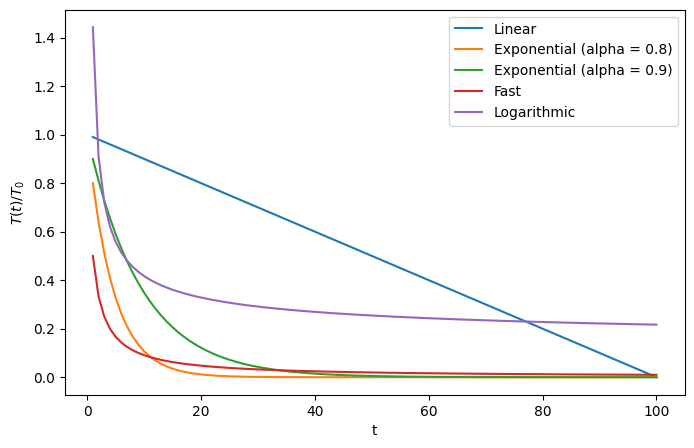

In [7]:
time = np.arange(1, 101)
initial_temperature = 1

schedules = {
    "Linear": temperature_linear(time, initial_temperature, eta=0.01),
    "Exponential (alpha = 0.8)": temperature_exponential(
        time, initial_temperature, alpha=0.8
    ),
    "Exponential (alpha = 0.9)": temperature_exponential(
        time, initial_temperature, alpha=0.9
    ),
    "Fast": temperature_fast(time, initial_temperature),
    "Logarithmic": temperature_logarithmic(time, initial_temperature),
}

plt.figure(figsize=(8, 5))
for name, temperature in schedules.items():
    plt.plot(time, temperature / initial_temperature, label=name)

plt.xlabel("t")
plt.ylabel(r"$T(t) / T_0$")
plt.legend()
plt.show()

## Literature

1. Kirkpatrick, S., Gelatt, C. D. Jr., and Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220, 671–680.
2. Hajek, B. (1988). Cooling schedules for optimal annealing. *Mathematics of Operations Research*, 13, 311–329.
3. Szu, H., and Hartley, R. (1987). Fast simulated annealing. *Physics Letters A*, 122(3–4), 157–162. [doi:10.1016/0375-9601(87)90796-1](https://doi.org/10.1016/0375-9601(87)90796-1)

## Bài 5 – Khảo sát tham số: lịch nào chấp nhận bước xấu lâu hơn?

,Số vòng còn T > 0.217 (trong 2000),T tại t=2000
Exponential α=0.99,151,0.0000
Exponential α=0.999,1526,0.1352
Linear η=0.001,782,0.0000
Linear η=0.0005,1565,0.0000
Fast,3,0.0005
Logarithmic,98,0.1316
Logarithmic T0=3,2000,0.3947


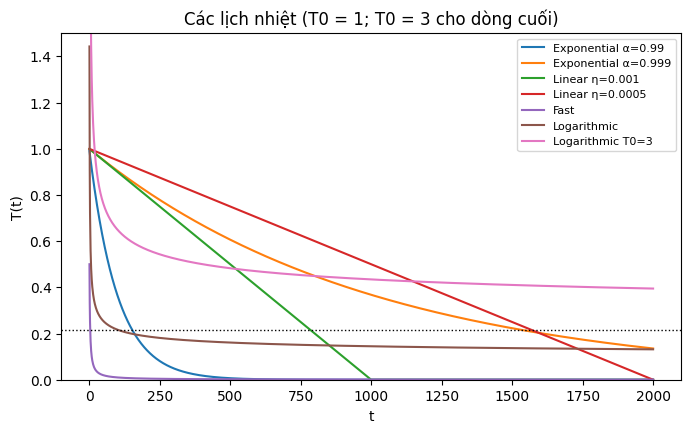

In [8]:
# Chấp nhận bước xấu Δ = 1 với xác suất exp(-1/T). Ta đếm số vòng lặp mà xác suất này còn > 1%  <=>  T > 1/ln(100) ≈ 0.217 (T0 = 1)
t = np.arange(1, 2001)
thr = 1 / np.log(100)
variants = {
    "Exponential α=0.99":   temperature_exponential(t, 1, 0.99),
    "Exponential α=0.999":  temperature_exponential(t, 1, 0.999),
    "Linear η=0.001":       np.maximum(temperature_linear(t, 1, 0.001), 1e-9),
    "Linear η=0.0005":      np.maximum(temperature_linear(t, 1, 0.0005), 1e-9),
    "Fast":                 temperature_fast(t, 1),
    "Logarithmic":          temperature_logarithmic(t, 1),
    "Logarithmic T0=3":     temperature_logarithmic(t, 3),
}
import pandas as pd
display(pd.DataFrame({"Số vòng còn T > 0.217 (trong 2000)": {k: int((v > thr).sum()) for k, v in variants.items()},
                      "T tại t=2000": {k: round(float(v[-1]), 4) for k, v in variants.items()}}))

plt.figure(figsize=(8, 4.5))
for k, v in variants.items(): plt.plot(t, v, label=k)
plt.axhline(thr, color="k", ls=":", lw=1); plt.ylim(0, 1.5)
plt.xlabel("t"); plt.ylabel("T(t)"); plt.title("Các lịch nhiệt (T0 = 1; T0 = 3 cho dòng cuối)"); plt.legend(fontsize=8); plt.show()

### Nhận xét
* **Logarithmic** T₀/ln(1+t) giảm nhanh lúc đầu (với T₀ = 1, dưới ngưỡng 0.217 chỉ sau ~100 vòng; T₀/ln 2 ≈ 1.44·T₀ ở t = 1 vì định nghĩa chỉ dùng t > 0) nhưng có **đuôi rất dài**: sau 2000 vòng vẫn ≈ 0.13·T₀, cao hơn cả mũ α = 0.99 và tuyến tính (đã về ~0). Nó không bao giờ “đóng băng” hẳn, nên còn chấp nhận được các bước xấu nhỏ rất lâu; lý thuyết bảo đảm tối ưu toàn cục khi T₀ ≥ rào cản năng lượng lớn nhất và chạy vô hạn, nhưng trong thực tế rất chậm. Với T₀ lớn hơn (T₀ = 3) nó giữ T > ngưỡng suốt 2000 vòng.
* **Tuyến tính** T₀ − ηt giảm đều về 0; η nhỏ hơn ⇒ chấp nhận bước xấu lâu hơn (η = 0.0005: 1565 vòng trên ngưỡng, gấp đôi η = 0.001: 782 vòng). Với T₀ = 1, đây và mũ α = 0.999 là hai lịch giữ T trên ngưỡng lâu nhất.
* **Mũ** T₀αᵗ: α càng gần 1 càng nguội chậm (α = 0.999: 1526 vòng trên ngưỡng, gấp ~10 lần α = 0.99: 151 vòng); sau đó T giảm rất nhanh về 0 nên chuyển hẳn sang khai thác.
* **Fast** T₀/(1+t) nguội nhanh nhất ban đầu (hyperbol) ⇒ chấp nhận bước xấu ngắn nhất.
* T₀ lớn hơn dời toàn bộ đường cong lên ⇒ kéo dài giai đoạn khám phá (dòng “T0=3”).
* Với bài n-Queens (Task 5 trong `n_queens.ipynb`, T₀ = 1) cả sáu lịch đạt 96–100% nghiệm trên 8-Queens; lịch tuyến tính cần nhiều vòng nhất (~3500) vì T còn cao quá lâu, logarithmic ít nhất (~830) vì nhiệt độ rơi nhanh về vùng ~0.2–0.3 (vừa đủ để thoát cực trị) – xem bảng trong `n_queens.ipynb`.